# Product Analytics: What Drives Product Performance in the Beauty Market?

## Project Objective

This project analyses Sephora product data to explore how product characteristics such as category, brand and price are associated with consumer response.

Product performance is examined using customer ratings and engagement metrics, including product loves and reviews. The analysis aims to identify patterns in product performance and determine which characteristics are most strongly associated with consumer engagement.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("product_info.csv")

## 1. Data Overview

The analysis uses the Sephora Products and Skincare Reviews dataset. For this project, `product_info.csv` was used, containing 8,494 products and 27 variables covering product characteristics, pricing, ratings and consumer engagement.

Key variables used in the analysis include:

- **brand_name** — product brand
- **primary_category** — main product category
- **price_usd** — listed product price
- **rating** — average customer rating
- **reviews** — number of customer reviews
- **loves_count** — number of users who marked the product as "loved"

In [3]:
df.head()


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
3,P473660,Kasbah Eau de Parfum,6342,19-69,3018,4.4762,21.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
4,P473658,Purple Haze Eau de Parfum,6342,19-69,2691,3.2308,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [4]:
df.shape

(8494, 27)

In [5]:
df.columns

Index(['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count',
       'rating', 'reviews', 'size', 'variation_type', 'variation_value',
       'variation_desc', 'ingredients', 'price_usd', 'value_price_usd',
       'sale_price_usd', 'limited_edition', 'new', 'online_only',
       'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category',
       'secondary_category', 'tertiary_category', 'child_count',
       'child_max_price', 'child_min_price'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8494 entries, 0 to 8493
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          8494 non-null   object 
 1   product_name        8494 non-null   object 
 2   brand_id            8494 non-null   int64  
 3   brand_name          8494 non-null   object 
 4   loves_count         8494 non-null   int64  
 5   rating              8216 non-null   float64
 6   reviews             8216 non-null   float64
 7   size                6863 non-null   object 
 8   variation_type      7050 non-null   object 
 9   variation_value     6896 non-null   object 
 10  variation_desc      1250 non-null   object 
 11  ingredients         7549 non-null   object 
 12  price_usd           8494 non-null   float64
 13  value_price_usd     451 non-null    float64
 14  sale_price_usd      270 non-null    float64
 15  limited_edition     8494 non-null   int64  
 16  new   

In [7]:
df.describe()


,brand_id,loves_count,rating,reviews,price_usd,value_price_usd,sale_price_usd,limited_edition,new,online_only,out_of_stock,sephora_exclusive,child_count,child_max_price,child_min_price
count,8494.000000,8.494000e+03,8216.000000,8216.000000,8494.000000,451.000000,270.000000,8494.000000,8494.000000,8494.000000,8494.000000,8494.000000,8494.000000,2754.000000,2754.000000
mean,5422.440546,2.917957e+04,4.194513,448.545521,51.655595,91.168537,20.207889,0.070285,0.071698,0.219096,0.073699,0.279374,1.631622,53.792023,39.665802
std,1709.595957,6.609212e+04,0.516694,1101.982529,53.669234,79.195631,24.327352,0.255642,0.258002,0.413658,0.261296,0.448718,5.379470,58.765894,38.685720
min,1063.000000,0.000000e+00,1.000000,1.000000,3.000000,0.000000,1.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,3.000000
25%,5333.000000,3.758000e+03,3.981725,26.000000,25.000000,45.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22.000000,19.000000
50%,6157.500000,9.880000e+03,4.289350,122.000000,35.000000,67.000000,14.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,32.000000,28.000000
75%,6328.000000,2.684125e+04,4.530525,418.000000,58.000000,108.500000,25.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,59.000000,42.000000
max,8020.000000,1.401068e+06,5.000000,21281.000000,1900.000000,617.000000,320.000000,1.000000,1.000000,1.000000,1.000000,1.000000,105.000000,570.000000,400.000000


## 2. Data Cleaning & Preparation

Before analysis, the dataset was assessed for missing values and duplicate records to ensure that the variables used in the analysis were suitable and reliable.

Missing values were handled according to the analysis being performed rather than removing incomplete rows from the entire dataset. Products without ratings and reviews were excluded from rating and review based analysis but were kept for engagement analysis where `loves_count` data remained available.

The dataset was also checked for both completely duplicated rows and duplicate product IDs.


In [8]:
df.isnull().sum()

product_id               0
product_name             0
brand_id                 0
brand_name               0
loves_count              0
rating                 278
reviews                278
size                  1631
variation_type        1444
variation_value       1598
variation_desc        7244
ingredients            945
price_usd                0
value_price_usd       8043
sale_price_usd        8224
limited_edition          0
new                      0
online_only              0
out_of_stock             0
sephora_exclusive        0
highlights            2207
primary_category         0
secondary_category       8
tertiary_category      990
child_count              0
child_max_price       5740
child_min_price       5740
dtype: int64

In [9]:
df[df["rating"].isnull()][
    ["product_name", "brand_name", "rating", "reviews", "loves_count", "price_usd"]
].head(10)

,product_name,brand_name,rating,reviews,loves_count,price_usd
42,Arancia di Capri Candle,Acqua di Parma,NaN,NaN,601,82.0
60,Mini Baomint Moisturizing Curl Defining Gel,adwoa beauty,NaN,NaN,0,14.0
61,Mini Baomint Moisturizing Curl Defining Cream,adwoa beauty,NaN,NaN,0,14.0
62,Mini Baomint Leave-In Conditioning Styler,adwoa beauty,NaN,NaN,0,13.0
63,Mini Baomint Moisturizing Shampoo,adwoa beauty,NaN,NaN,0,12.0
64,Mini Baomint Protect + Shine Oil Blend,adwoa beauty,NaN,NaN,0,11.0
84,Perfume Sampler Discovery Set,AERIN,NaN,NaN,1376,25.0
88,Mediterranean Honeysuckle Mimosa Eau de Parfum...,AERIN,NaN,NaN,0,30.0
121,Algae Peptide Regenerative Moisturizer,Algenist,NaN,NaN,442,98.0
188,Clinical Densifying Styling Mousse,ALTERNA Haircare,NaN,NaN,0,38.0


In [10]:
df[df["rating"].isnull()]["reviews"].isnull().sum()

np.int64(278)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["product_id"].duplicated().sum()

np.int64(0)

**Cleaning summary:** 278 products had missing values for both ratings and reviews. These records were kept where other available variables could still contribute to the analysis. No completely duplicated records or duplicate product IDs were identified.

### 3.1 Product Categories

In [13]:
df["primary_category"].value_counts()

primary_category
Skincare           2420
Makeup             2369
Hair               1464
Fragrance          1432
Bath & Body         405
Mini Size           288
Men                  60
Tools & Brushes      52
Gifts                 4
Name: count, dtype: int64

The dataset is primarily composed of Skincare and Makeup products, followed by Hair and Fragrance. Some categories contain substantially fewer products, which is considered when interpreting later category-level comparisons.

### 3.2 Product Ratings

In [14]:
df["rating"].describe()

count    8216.000000
mean        4.194513
std         0.516694
min         1.000000
25%         3.981725
50%         4.289350
75%         4.530525
max         5.000000
Name: rating, dtype: float64

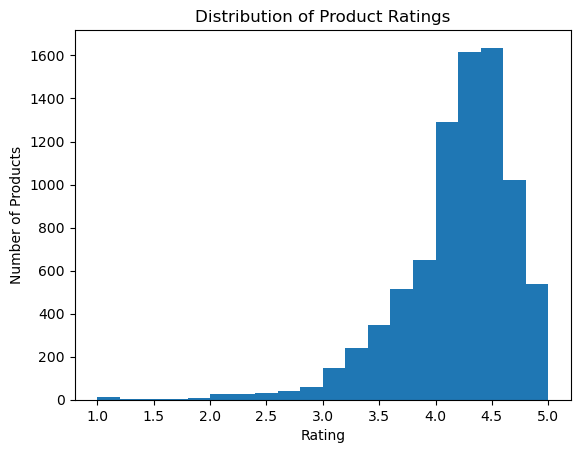

In [15]:
plt.hist(df["rating"].dropna(), bins=20)
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Ratings")
plt.show()

### 3.3 Consumer Engagement

In [16]:
df["loves_count"].describe()

count    8.494000e+03
mean     2.917957e+04
std      6.609212e+04
min      0.000000e+00
25%      3.758000e+03
50%      9.880000e+03
75%      2.684125e+04
max      1.401068e+06
Name: loves_count, dtype: float64

In [17]:
df["loves_count"].quantile(0.95)

np.float64(112628.24999999994)

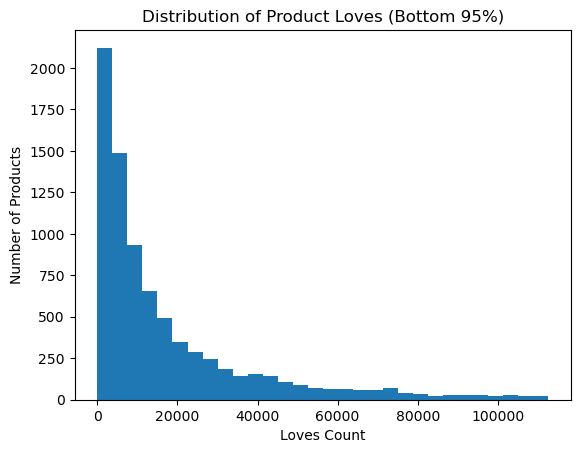

In [18]:
plt.hist(df[df["loves_count"] <= 112628]["loves_count"], bins=30)
plt.xlabel("Loves Count")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Loves (Bottom 95%)")
plt.show()

Consumer engagement was highly right-skewed. The median product received 9,880 loves, compared with a mean of approximately 29,180, indicating that a relatively small number of highly popular products substantially increased the average.

For visual clarity, the second histogram displays the bottom 95% of products by loves count. This visual excludes only the highest-engagement products, which remain in the dataset for subsequent analysis.

### 3.4 Product Price

In [19]:
df["price_usd"].describe()

count    8494.000000
mean       51.655595
std        53.669234
min         3.000000
25%        25.000000
50%        35.000000
75%        58.000000
max      1900.000000
Name: price_usd, dtype: float64

Product prices were right-skewed, with a median price of $35 compared with a mean of approximately $51.66. This difference reflects the presence of a smaller number of substantially more expensive products.

## 4. Relationships Between Product Characteristics and Performance

Correlations and scatter plots were used to examine how product ratings, price and review activity were associated with consumer engagement.

### 4.1 Rating and Consumer Engagement

In [20]:
df["rating"].corr(df["loves_count"])

np.float64(0.04179718344886662)

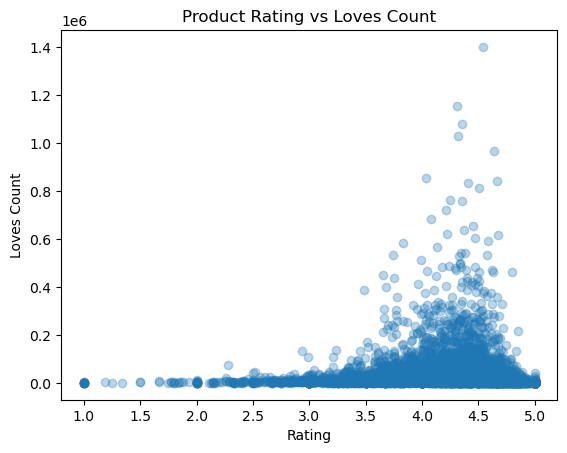

In [21]:
plt.scatter(df["rating"], df["loves_count"], alpha=0.3)
plt.xlabel("Rating")
plt.ylabel("Loves Count")
plt.title("Product Rating vs Loves Count")
plt.show()

Product rating showed almost no linear relationship with consumer engagement (r = 0.042). This suggests that highly rated products are not necessarily the products receiving the highest levels of engagement.

### 4.2 Price, Ratings and Consumer Engagement

In [22]:
df["price_usd"].corr(df["rating"])

np.float64(0.05673783999653352)

In [23]:
df["price_usd"].corr(df["loves_count"])

np.float64(-0.08960660579128278)

Price showed almost no linear relationship with either product rating (r = 0.057) or consumer engagement (r = -0.090). This suggests that higher-priced products were not meaningfully associated with higher customer ratings or greater engagement within this dataset.

### 4.3 Reviews and Consumer Engagement

In [24]:
df["reviews"].corr(df["loves_count"])

np.float64(0.683786292736817)

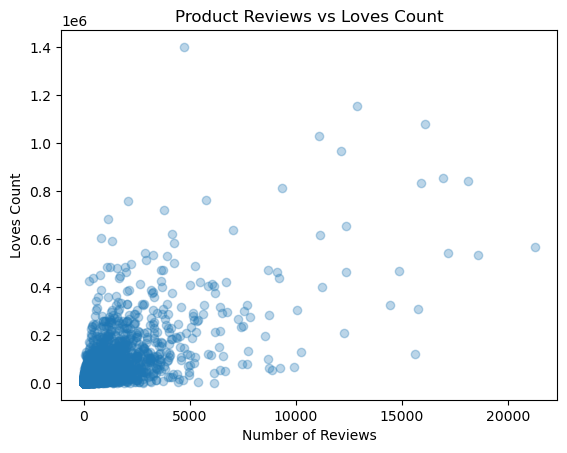

In [25]:
plt.scatter(df["reviews"], df["loves_count"], alpha=0.3)
plt.xlabel("Number of Reviews")
plt.ylabel("Loves Count")
plt.title("Product Reviews vs Loves Count")
plt.show()

Reviews and loves showed a moderately strong positive linear relationship (r = 0.684). Products receiving more reviews also tended to receive more loves, suggesting that the two measures capture related aspects of consumer engagement.

This relationship was substantially stronger than the relationships observed between engagement and either product rating or price. However, correlation does not establish that receiving more reviews causes a product to receive more loves.

## 5. Category and Brand Analysis

Product performance was compared across categories and brands to examine whether consumer engagement varied across different segments of the Sephora catalogue.

### 5.1 Product Category Analysis

In [26]:
category_summary = df.groupby("primary_category").agg(
    product_count=("product_id", "count"),
    median_loves=("loves_count", "median"),
    median_rating=("rating", "median"),
    median_price=("price_usd", "median")
)

category_summary

,product_count,median_loves,median_rating,median_price
primary_category,,,,
Bath & Body,405,6453.0,4.2813,38.0
Fragrance,1432,5126.0,4.3333,80.0
Gifts,4,0.0,4.5681,50.0
Hair,1464,6404.0,4.2946,32.0
Makeup,2369,22387.0,4.2523,29.0
Men,60,4057.0,4.5827,30.0
Mini Size,288,11359.0,4.1177,18.0
Skincare,2420,10073.5,4.3111,44.0
Tools & Brushes,52,9786.0,4.4169,19.5


In [27]:
large_categories = category_summary[category_summary["product_count"] >= 100]

large_categories

,product_count,median_loves,median_rating,median_price
primary_category,,,,
Bath & Body,405,6453.0,4.2813,38.0
Fragrance,1432,5126.0,4.3333,80.0
Hair,1464,6404.0,4.2946,32.0
Makeup,2369,22387.0,4.2523,29.0
Mini Size,288,11359.0,4.1177,18.0
Skincare,2420,10073.5,4.3111,44.0


In [28]:
large_categories = large_categories.sort_values("median_loves", ascending=False)
large_categories

,product_count,median_loves,median_rating,median_price
primary_category,,,,
Makeup,2369,22387.0,4.2523,29.0
Mini Size,288,11359.0,4.1177,18.0
Skincare,2420,10073.5,4.3111,44.0
Bath & Body,405,6453.0,4.2813,38.0
Hair,1464,6404.0,4.2946,32.0
Fragrance,1432,5126.0,4.3333,80.0


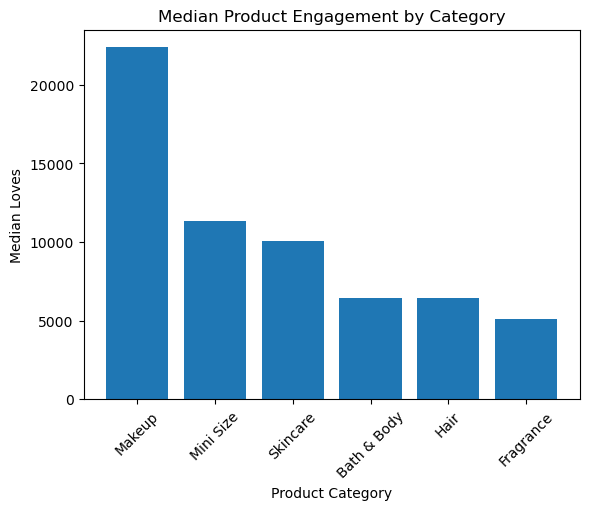

In [29]:
plt.bar(large_categories.index, large_categories["median_loves"])

plt.xlabel("Product Category")
plt.ylabel("Median Loves")
plt.title("Median Product Engagement by Category")

plt.xticks(rotation=45)
plt.show()

Among the larger product categories, Makeup showed the highest median consumer engagement, with 22,387 loves per product. This was substantially higher than Skincare (10,074), Hair (6,404) and Fragrance (5,126), despite broadly similar median customer ratings across these categories.

The comparison was restricted to categories containing at least 100 products to reduce the influence of very small groups. These results indicate that consumer engagement varies considerably across product categories, with Makeup standing out within the Sephora catalogue.

### 5.2 Brand Analysis

In [30]:
df["brand_name"].value_counts().head(10)

brand_name
SEPHORA COLLECTION         352
CLINIQUE                   179
Dior                       136
tarte                      131
NEST New York              115
Bumble and bumble          110
Kérastase                  108
TOM FORD                   100
Charlotte Tilbury           99
Anastasia Beverly Hills     95
Name: count, dtype: int64

In [31]:
brand_summary = df.groupby("brand_name").agg(
    product_count=("product_id", "count"),
    median_loves=("loves_count", "median"),
    median_rating=("rating", "median"),
    median_price=("price_usd", "median")
)

large_brands = brand_summary[brand_summary["product_count"] >= 30]

large_brands.sort_values("median_loves", ascending=False).head(10)

,product_count,median_loves,median_rating,median_price
brand_name,,,,
Rare Beauty by Selena Gomez,40,72310.5,4.33840,22.00
The Ordinary,54,68842.0,4.16500,10.00
Fenty Beauty by Rihanna,82,54307.0,4.11760,28.00
Sol de Janeiro,43,51711.0,4.23025,26.00
Too Faced,62,38835.0,4.20000,28.00
The INKEY List,47,36241.0,4.15580,12.99
ILIA,31,35799.0,4.13690,28.00
MILK MAKEUP,49,35156.0,4.04530,28.00
HUDA BEAUTY,59,34639.0,4.09865,28.00


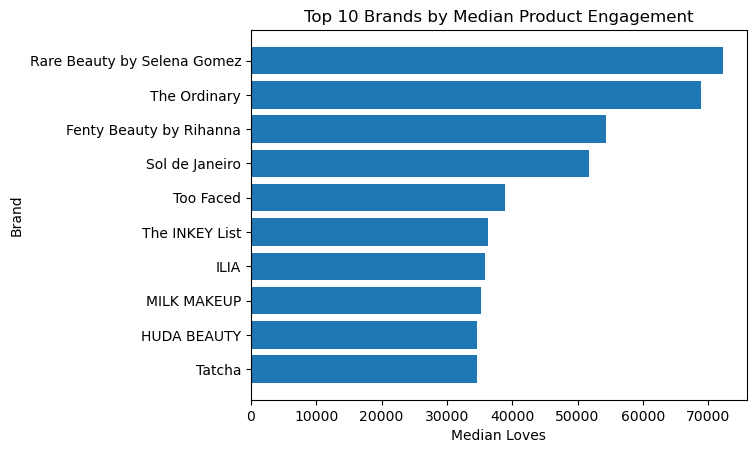

In [32]:
top_brands = large_brands.sort_values("median_loves", ascending=False).head(10)

plt.barh(top_brands.index, top_brands["median_loves"])
plt.xlabel("Median Loves")
plt.ylabel("Brand")
plt.title("Top 10 Brands by Median Product Engagement")
plt.gca().invert_yaxis()
plt.show()

Among brands with at least 30 listed products, median consumer engagement varied substantially. Rare Beauty and The Ordinary recorded the highest median loves counts, with approximately 72,311 and 68,842 respectively.

The leading brands also varied considerably in median price. For example, Rare Beauty had a median price of $22 compared with $10 for The Ordinary, while both showed high median engagement. This is consistent with the earlier finding that price alone had little linear relationship with consumer engagement.

I excluded brands with fewer than 30 products from this comparison to reduce the influence of very small product ranges.

### 5.3 Top-Performing Products

In [33]:
top_products = df.sort_values("loves_count", ascending=False)[
    ["product_name", "brand_name", "primary_category", 
     "price_usd", "rating", "reviews", "loves_count"]
].head(10)

top_products

,product_name,brand_name,primary_category,price_usd,rating,reviews,loves_count
6242,Soft Pinch Liquid Blush,Rare Beauty by Selena Gomez,Makeup,23.0,4.5356,4733.0,1401068
5249,Radiant Creamy Concealer,NARS,Makeup,32.0,4.3080,12887.0,1153594
4431,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Skincare,24.0,4.3508,16118.0,1081315
6434,Cream Lip Stain Liquid Lipstick,SEPHORA COLLECTION,Makeup,15.0,4.3201,11111.0,1029051
2523,Gloss Bomb Universal Lip Luminizer,Fenty Beauty by Rihanna,Makeup,21.0,4.6357,12136.0,968317
2524,Pro Filt’r Soft Matte Longwear Liquid Foundation,Fenty Beauty by Rihanna,Makeup,40.0,4.0356,16935.0,856497
5250,Blush,NARS,Makeup,32.0,4.6643,18127.0,840076
247,Brow Wiz Ultra-Slim Precision Brow Pencil,Anastasia Beverly Hills,Makeup,25.0,4.4056,15885.0,834189
4458,Translucent Loose Setting Powder,Laura Mercier,Makeup,43.0,4.5029,9335.0,813497
7648,Niacinamide 10% + Zinc 1% Oil Control Serum,The Ordinary,Skincare,6.0,4.2439,5778.0,763168


In [34]:
top_products["primary_category"].value_counts()

primary_category
Makeup      8
Skincare    2
Name: count, dtype: int64

Eight of the ten products with the highest loves counts were Makeup products, while the remaining two were Skincare products. This is consistent with the category-level analysis, where Makeup recorded the highest median engagement among the larger product categories.

The most-loved products also covered a range of prices and ratings, further illustrating that high consumer engagement does not necessarily correspond to either a higher price or the highest customer rating.

## 6. Key Findings and Business Implications

The analysis essentially highlights that product performance within Sephora is multidimensional. Customer ratings were generally high across products, while consumer engagement varied substantially.

Product rating and price showed very weak linear relationships with loves, suggesting that neither higher ratings nor higher prices were strongly associated with greater consumer engagement. In contrast, review volume showed a much stronger positive relationship with loves (r = 0.684), indicating that these two metrics capture related aspects of consumer activity.

Clear differences in engagement were also observed across product categories and brands. Makeup recorded the highest median engagement among the larger categories, and eight of the ten most-loved individual products were Makeup products. At brand level, Rare Beauty and The Ordinary showed particularly high median engagement among brands with at least 30 listed products.

From a business perspective, these findings suggest that customer rating alone should not be treated as a measure of product popularity. Ratings provide information about customer satisfaction, while metrics such as loves and reviews show popularity and provide a different view of consumer engagement. Product performance should therefore be evaluated using multiple measures and interpreted within the context of category and brand.

## 7. Limitations and Conclusion

### Limitations

This analysis is based on a snapshot of products listed within the Sephora dataset and therefore may not represent the wider beauty market. Consumer engagement measures such as loves and reviews are cumulative and may be influenced by factors not captured in the dataset, including product age, marketing activity,current trends, brand awareness and product availability.

The analysis identifies associations rather than causal relationships. Correlations between variables should therefore not be interpreted as evidence that one factor directly causes changes in another. Category and brand comparisons are also descriptive, and minimum product-count thresholds were used to reduce the influence of very small groups.

### Conclusion

Overall, the analysis demonstrates that product performance cannot be represented by a single factor. While customer ratings were consistently high across much of the dataset, consumer engagement varied considerably across products, categories and brands.

Price and customer rating showed little linear relationship with product loves, while review activity was much more strongly associated with engagement. Category and brand context also revealed substantial differences in typical engagement, with Makeup particularly prominent within the dataset.

These findings demonstrate the importance of combining satisfaction, engagement and product characteristics when evaluating any product performance.